# 5 · Kwantowy dylemat więźnia

**Koło Naukowe Qubit, PWr** · teoria gier na 2 kubitach (Qiskit + IQM)

Dwóch więźniów, Ala i Bartek, nie może się dogadać. Każde wybiera: **współpracuję** (C) albo **zdradzam** (D).
Klasycznie zdrada zawsze się opłaca, więc oboje zdradzają i oboje tracą. Gdy dołożymy **splątanie**,
pojawia się nowa strategia Q, która z tej pułapki wychodzi. A potem okazuje się, że najlepsza strategia to… losowanie.

Plan:
1. Klasyczny dylemat: dlaczego oboje zdradzają.
2. Protokół Eiserta, Wilkensa i Lewensteina (1999): gra na 2 kubitach.
3. Strategia Q i splątanie jako pokrętło.
4. Gracze, którzy się uczą: czy sami znajdą Q?
5. Pełna przestrzeń strategii: każda strategia ma kontrę, jak w kamień, papier, nożyce. Wygrywa losowość.
6. Wszystko na modelu Odry 5 z szumem.

> 📚 J. Eisert, M. Wilkens, M. Lewenstein, *Quantum Games and Quantum Strategies*, Phys. Rev. Lett. 83, 3077 (1999).
> S. C. Benjamin, P. M. Hayden, komentarz do tej pracy, Phys. Rev. Lett. 87, 069801 (2001).

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector
from iqm.qiskit_iqm import IQMFakeAdonis

adonis = IQMFakeAdonis()
rng = np.random.default_rng(0)

## 1. Klasyczny dylemat

Punkty (więcej = lepiej), pierwsza liczba dla Ali, druga dla Bartka:

| | Bartek: C | Bartek: D |
|---|---|---|
| **Ala: C** | 3, 3 | 0, 5 |
| **Ala: D** | 5, 0 | 1, 1 |

Spójrz oczami Ali. Jeśli Bartek współpracuje: C daje 3, D daje 5, więc lepiej zdradzić.
Jeśli Bartek zdradza: C daje 0, D daje 1, więc też lepiej zdradzić. Zdrada wygrywa **zawsze**.
Bartek myśli tak samo. Wynik: (1, 1), choć (3, 3) było w zasięgu.

Taki punkt, z którego nikomu nie opłaca się samemu zmienić strategii, to **równowaga Nasha**.

In [3]:
PAYOFF_ALICE = np.array([3, 0, 5, 1])   # indeks = 2 * (Ala zdradza) + (Bartek zdradza)
PAYOFF_BOB = np.array([3, 5, 0, 1])
NAMES = "CD"

for a in range(2):
    for b in range(2):
        pa, pb = PAYOFF_ALICE[2 * a + b], PAYOFF_BOB[2 * a + b]
        alice_better = PAYOFF_ALICE[2 * (1 - a) + b] > pa
        bob_better = PAYOFF_BOB[2 * a + (1 - b)] > pb
        nash = not alice_better and not bob_better
        print(f"Ala {NAMES[a]}, Bartek {NAMES[b]}: ({pa}, {pb})   {'<- równowaga Nasha' if nash else ''}")

Ala C, Bartek C: (3, 3)   
Ala C, Bartek D: (0, 5)   
Ala D, Bartek C: (5, 0)   
Ala D, Bartek D: (1, 1)   <- równowaga Nasha


## 2. Gra na kubitach

Każdy gracz ma jeden kubit. `0` znaczy C, `1` znaczy D.

1. **Sędzia** splata kubity bramką $J(\gamma)$. Parametr $\gamma$ to „ile splątania”: 0 = wcale, $\pi/2$ = maksymalnie.
2. **Gracze** w osobnych pokojach obracają swój kubit bramką
   $$U(\theta, \varphi) = \begin{pmatrix} e^{i\varphi}\cos\frac{\theta}{2} & \sin\frac{\theta}{2} \\ -\sin\frac{\theta}{2} & e^{-i\varphi}\cos\frac{\theta}{2} \end{pmatrix}$$
3. **Sędzia** cofa splątanie ($J^\dagger$) i mierzy oba kubity. Wynik pomiaru to ruchy C/D, punkty z tabeli.

Trzy ważne strategie:
- **C** = $U(0, 0)$, nic nie rób,
- **D** = $U(\pi, 0)$, odwróć kubit,
- **Q** = $U(0, \pi/2)$, tylko zmiana fazy. Klasycznie nie ma odpowiednika.

Gdy $\gamma = 0$, $J$ nic nie robi i dostajemy zwykłą grę: C i D działają jak klasyczne ruchy, a Q jak C.

W Qiskit $J(\gamma)$ to bramka `RYY(γ)`.

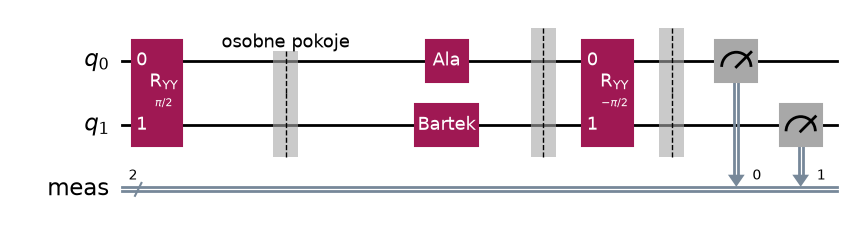

In [4]:
def strategy(theta, phi):
    c, s = np.cos(theta / 2), np.sin(theta / 2)
    return np.array([[np.exp(1j * phi) * c, s], [-s, np.exp(-1j * phi) * c]])

C = strategy(0, 0)
D = strategy(np.pi, 0)
Q = strategy(0, np.pi / 2)
FULL = np.pi / 2   # maksymalne splątanie

def game_circuit(UA, UB, gamma=FULL, measure=True):
    qc = QuantumCircuit(2)                 # kubit 0 = Ala, kubit 1 = Bartek
    qc.ryy(gamma, 0, 1)                    # sędzia splata
    qc.barrier(label="osobne pokoje")
    qc.append(UnitaryGate(UA, label="Ala"), [0])
    qc.append(UnitaryGate(UB, label="Bartek"), [1])
    qc.barrier()
    qc.ryy(-gamma, 0, 1)                   # sędzia cofa splątanie
    if measure:
        qc.measure_all()
    return qc

game_circuit(Q, D).draw("mpl")

Do liczenia wielu partii używamy wzoru na macierzach $4 \times 4$ (szybciej niż Qiskit),
i sprawdzamy, że daje to samo:

In [5]:
YY = np.kron([[0, -1j], [1j, 0]], [[0, -1j], [1j, 0]])

def J(gamma):
    return np.cos(gamma / 2) * np.eye(4) - 1j * np.sin(gamma / 2) * YY

def outcome_probs(UA, UB, gamma=FULL):
    # prawdopodobieństwa wyników CC, CD, DC, DD (indeks = 2 * Ala + Bartek)
    psi = J(-gamma) @ np.kron(UA, UB) @ J(gamma) @ np.array([1, 0, 0, 0])
    return np.abs(psi) ** 2

def payoffs(UA, UB, gamma=FULL):
    p = outcome_probs(UA, UB, gamma)
    return p @ PAYOFF_ALICE, p @ PAYOFF_BOB

UA, UB = strategy(1.0, 0.3), strategy(2.0, 1.1)
qiskit_p = Statevector(game_circuit(UA, UB, measure=False)).probabilities_dict()
qiskit_p = [qiskit_p.get(f"{b}{a}", 0) for a in "01" for b in "01"]   # Qiskit pisze "Bartek Ala"
print("macierze:", np.round(outcome_probs(UA, UB), 4))
print("Qiskit:  ", np.round(qiskit_p, 4))
assert np.allclose(outcome_probs(UA, UB), qiskit_p)

macierze: [0.0065 0.2253 0.0101 0.7581]
Qiskit:   [0.0065 0.2253 0.0101 0.7581]


## 3. Strategia Q

In [6]:
S = {"C": C, "D": D, "Q": Q}
for gamma, title in [(0, "bez splątania"), (FULL, "maksymalne splątanie")]:
    print(f"{title}:")
    print("          " + "".join(f"Bartek {b:3}" for b in S))
    for a, UA in S.items():
        print(f"Ala {a:5} " + "".join(f"({payoffs(UA, UB, gamma)[0]:.0f}, {payoffs(UA, UB, gamma)[1]:.0f})".ljust(10) for UB in S.values()))
    print()

bez splątania:
          Bartek C  Bartek D  Bartek Q  
Ala C     (3, 3)    (0, 5)    (3, 3)    
Ala D     (5, 0)    (1, 1)    (5, 0)    
Ala Q     (3, 3)    (0, 5)    (3, 3)    

maksymalne splątanie:
          Bartek C  Bartek D  Bartek Q  
Ala C     (3, 3)    (0, 5)    (1, 1)    
Ala D     (5, 0)    (1, 1)    (0, 5)    
Ala Q     (1, 1)    (5, 0)    (3, 3)    



Przy splątaniu:
- (Q, Q) daje **(3, 3)**, czyli wynik współpracy.
- Zdrada przeciw Q się nie opłaca: (D, Q) daje Ali 0, a nie 5. Za to Q karze zdrajcę: (Q, D) daje Ali 5.

Czy (Q, Q) to równowaga? Szukamy najlepszej odpowiedzi Ali na Q wśród wszystkich $U(\theta, \varphi)$:

In [7]:
thetas = np.linspace(0, np.pi, 91)
phis = np.linspace(0, np.pi / 2, 91)
grid = np.array([[payoffs(strategy(t, f), Q)[0] for t in thetas] for f in phis])
i, j = np.unravel_index(grid.argmax(), grid.shape)
print(f"najlepsza odpowiedź Ali na Q: θ = {thetas[j]:.2f}, φ = {phis[i]:.2f}, punkty = {grid.max():.2f}  (to jest Q)")

najlepsza odpowiedź Ali na Q: θ = 0.00, φ = 1.57, punkty = 3.00  (to jest Q)


Tak: najlepsza odpowiedź na Q to Q. Więc (Q, Q) to równowaga Nasha z wynikiem (3, 3).

Klasyczny obrazek z pracy EWL: strategie na jednej osi, od Q przez C do D. Kolor to punkty Ali.

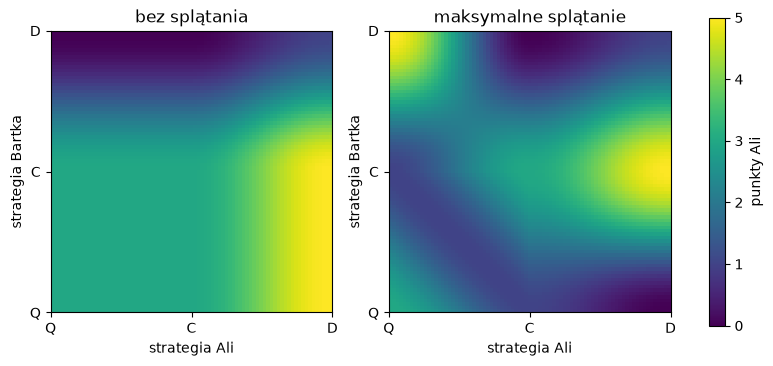

In [8]:
def axis_strategy(t):
    # t z [-1, 0]: od Q do C (rośnie φ), t z [0, 1]: od C do D (rośnie θ)
    return strategy(t * np.pi, 0) if t >= 0 else strategy(0, -t * np.pi / 2)

ts = np.linspace(-1, 1, 81)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, gamma, title in [(axes[0], 0, "bez splątania"), (axes[1], FULL, "maksymalne splątanie")]:
    Z = np.array([[payoffs(axis_strategy(ta), axis_strategy(tb), gamma)[0] for ta in ts] for tb in ts])
    im = ax.imshow(Z, origin="lower", extent=[-1, 1, -1, 1], cmap="viridis", vmin=0, vmax=5)
    ax.set_xticks([-1, 0, 1], ["Q", "C", "D"]); ax.set_yticks([-1, 0, 1], ["Q", "C", "D"])
    ax.set_xlabel("strategia Ali"); ax.set_ylabel("strategia Bartka"); ax.set_title(title)
fig.colorbar(im, ax=axes, label="punkty Ali")
plt.show()

### Splątanie jako pokrętło

Ile splątania trzeba, żeby Q działało? Liczymy, ile Ala zyska, jeśli Bartek gra Q, a ona zamiast Q zdradzi.
Gdy zysk jest dodatni, (Q, Q) przestaje być równowagą.

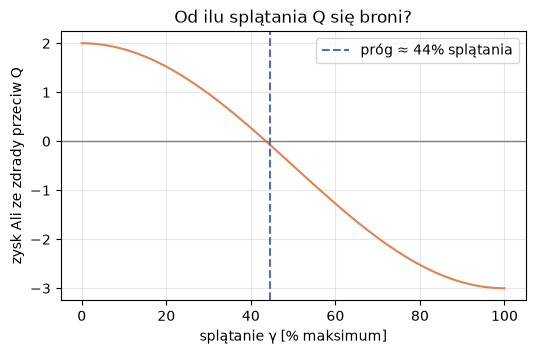

In [9]:
gammas = np.linspace(0, FULL, 91)
gain = np.array([payoffs(D, Q, g)[0] - payoffs(Q, Q, g)[0] for g in gammas])
threshold = gammas[np.argmax(gain <= 0)]

plt.figure(figsize=(6, 3.5))
plt.plot(gammas / FULL * 100, gain, color="#DD8452")
plt.axhline(0, color="gray", lw=1)
plt.axvline(threshold / FULL * 100, color="#4C72B0", ls="--", label=f"próg ≈ {threshold / FULL:.0%} splątania")
plt.xlabel("splątanie γ [% maksimum]"); plt.ylabel("zysk Ali ze zdrady przeciw Q")
plt.title("Od ilu splątania Q się broni?"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## 4. Gracze, którzy się uczą

Dwa „naiwne” boty: każdy po trochu zmienia swoje $(\theta, \varphi)$ w stronę, która daje mu więcej punktów
(wspinaczka po gradiencie). Startują z losowych strategii. 30 par botów, gra klasyczna kontra kwantowa.

gra klasyczna: (1.0, 1.0) x30


gra kwantowa: (0.9, 1.5) x1, (1.0, 1.0) x11, (3.0, 3.0) x18


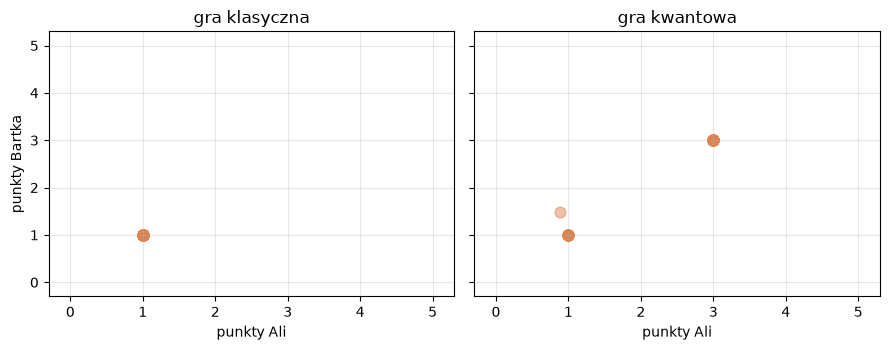

In [10]:
LOW, HIGH = np.array([0, 0]), np.array([np.pi, np.pi / 2])

def learn(gamma, steps=1500, lr=0.05, seed=0):
    r = np.random.default_rng(seed)
    a, b = r.uniform(LOW, HIGH), r.uniform(LOW, HIGH)
    h = 1e-4
    for _ in range(steps):
        ga = [(payoffs(strategy(*(a + h * e)), strategy(*b), gamma)[0] -
               payoffs(strategy(*(a - h * e)), strategy(*b), gamma)[0]) / (2 * h) for e in np.eye(2)]
        gb = [(payoffs(strategy(*a), strategy(*(b + h * e)), gamma)[1] -
               payoffs(strategy(*a), strategy(*(b - h * e)), gamma)[1]) / (2 * h) for e in np.eye(2)]
        a = np.clip(a + lr * np.array(ga), LOW, HIGH)
        b = np.clip(b + lr * np.array(gb), LOW, HIGH)
    return payoffs(strategy(*a), strategy(*b), gamma)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, gamma, title in [(axes[0], 0, "gra klasyczna"), (axes[1], FULL, "gra kwantowa")]:
    final = np.array([learn(gamma, seed=s) for s in range(30)])
    ax.scatter(final[:, 0], final[:, 1], s=60, alpha=0.5, color="#DD8452")
    ax.set_title(title); ax.set_xlabel("punkty Ali"); ax.set_xlim(-0.3, 5.3); ax.set_ylim(-0.3, 5.3); ax.grid(alpha=0.3)
    labels, counts = np.unique(np.round(final, 1), axis=0, return_counts=True)
    print(title + ":", ", ".join(f"({x:.1f}, {y:.1f}) x{n}" for (x, y), n in zip(labels, counts)))
axes[0].set_ylabel("punkty Bartka")
plt.tight_layout(); plt.show()

- W grze klasycznej boty **zawsze** kończą na zdradzie (1, 1).
- W grze kwantowej większość par sama znajduje Q i dostaje (3, 3).
- Część par utyka na (1, 1). Powód: przy $\theta = \pi$ (czyli D) kąt $\varphi$ nic nie zmienia,
  więc z D nie widać, że gdzieś dalej leży lepsza strategia. Gradient widzi tylko najbliższe otoczenie.

## 5. Pełna przestrzeń strategii: wygrywa losowość

Do tej pory gracze mieli tylko dwa kąty $(\theta, \varphi)$. Kubit można jednak obrócić **dowolnie**
(trzy kąty, cała grupa $SU(2)$). Benjamin i Hayden zauważyli, że wtedy Q przestaje działać:
na **każdą** strategię istnieje kontra. Sprawdźmy, szukając najlepszej odpowiedzi losowo wśród 5000 obrotów.

In [11]:
def any_rotation(a, b, c):
    return np.array([[np.exp(1j * a) * np.cos(b), np.exp(1j * c) * np.sin(b)],
                     [-np.exp(-1j * c) * np.sin(b), np.exp(-1j * a) * np.cos(b)]])

candidates = [any_rotation(*x) for x in rng.uniform(0, 2 * np.pi, (5000, 3))]

def best_response_bob(UA):
    return max(candidates, key=lambda UB: payoffs(UA, UB)[1])

def best_response_alice(UB):
    return max(candidates, key=lambda UA: payoffs(UA, UB)[0])

UA, UB = Q, Q
print("start: oboje grają Q ->", tuple(round(float(x), 2) for x in payoffs(UA, UB)))
for step in range(3):
    UB = best_response_bob(UA)
    print(f"Bartek kontruje       -> punkty (Ala, Bartek) = {tuple(round(float(x), 2) for x in payoffs(UA, UB))}")
    UA = best_response_alice(UB)
    print(f"Ala kontruje kontrę   -> punkty (Ala, Bartek) = {tuple(round(float(x), 2) for x in payoffs(UA, UB))}")

start: oboje grają Q -> (3.0, 3.0)


Bartek kontruje       -> punkty (Ala, Bartek) = (0.0, 5.0)


Ala kontruje kontrę   -> punkty (Ala, Bartek) = (5.0, 0.0)


Bartek kontruje       -> punkty (Ala, Bartek) = (0.0, 5.0)


Ala kontruje kontrę   -> punkty (Ala, Bartek) = (5.0, 0.0)


Bartek kontruje       -> punkty (Ala, Bartek) = (0.0, 5.0)


Ala kontruje kontrę   -> punkty (Ala, Bartek) = (5.0, 0.0)


Zawsze jest kontra dająca prawie 5 punktów. Gracze wiecznie się przeskakują, jak w kamień, papier, nożyce.
Nie ma czystej strategii, która byłaby równowagą.

Wyjście jest takie samo jak w kamień, papier, nożyce: **losowanie**. Niech każde gra losowo jedną z czterech bramek
$I, iX, iY, iZ$ (po 1/4). Losowa bramka Pauliego na połowie maksymalnie splątanej pary daje
całkowicie losowy wynik, cokolwiek zrobi przeciwnik. Każdy z 4 wyników ma szansę 1/4, więc punkty to
$(3 + 0 + 5 + 1)/4 = 2.25$.

In [12]:
X, Y, Z = np.array([[0, 1], [1, 0]]), np.array([[0, -1j], [1j, 0]]), np.diag([1, -1])
PAULIS = [np.eye(2), 1j * X, 1j * Y, 1j * Z]

def mixed_vs(UB):
    return np.mean([payoffs(P, UB) for P in PAULIS], axis=0)

for name, UB in [("C", C), ("D", D), ("Q", Q), ("losowy obrót", candidates[0]), ("inny losowy obrót", candidates[1])]:
    print(f"Ala losuje Pauliego, Bartek gra {name:18}-> punkty (Ala, Bartek) = {np.round(mixed_vs(UB), 2)}")

Ala losuje Pauliego, Bartek gra C                 -> punkty (Ala, Bartek) = [2.25 2.25]
Ala losuje Pauliego, Bartek gra D                 -> punkty (Ala, Bartek) = [2.25 2.25]
Ala losuje Pauliego, Bartek gra Q                 -> punkty (Ala, Bartek) = [2.25 2.25]
Ala losuje Pauliego, Bartek gra losowy obrót      -> punkty (Ala, Bartek) = [2.25 2.25]
Ala losuje Pauliego, Bartek gra inny losowy obrót -> punkty (Ala, Bartek) = [2.25 2.25]


Zawsze 2.25. Jeśli oboje losują w ten sposób, nikt nie zyska na zmianie strategii: to jest równowaga Nasha.

| gra | równowaga | punkty każdego |
|---|---|---|
| klasyczna | oboje zdradzają | 1 |
| kwantowa, 2 kąty | oboje grają Q | 3 |
| kwantowa, pełne obroty | oboje losują bramkę Pauliego | 2.25 |

Morał: splątanie pomaga (2.25 > 1), ale tylko z losowością. To ta sama lekcja co w kamień, papier, nożyce.

## 6. Na modelu Odry 5 z szumem

Kompilator mógłby uprościć te obwody (np. Q i Q razem z $J$ i $J^\dagger$ skracają się do zera bramek dwukubitowych).
W prawdziwej grze sędzia i gracze działają osobno, więc wyłączamy optymalizację (`optimization_level=0`)
i naprawdę wykonujemy splątanie.

In [13]:
SHOTS = 4000

def noisy_payoffs(UA, UB, shots=SHOTS, seed=1):
    qc = transpile(game_circuit(UA, UB), adonis, optimization_level=0, seed_transpiler=1)
    counts = adonis.run(qc, shots=shots, seed_simulator=seed).result().get_counts()
    p = np.zeros(4)
    for bits, n in counts.items():
        p[2 * int(bits[1]) + int(bits[0])] += n / shots     # bits = "Bartek Ala"
    return p @ PAYOFF_ALICE, p @ PAYOFF_BOB

def noisy_mixed(UB, shots=SHOTS):
    return np.mean([noisy_payoffs(P, UB, shots // 4, seed=k) for k, P in enumerate(PAULIS)], axis=0)

print("bramek CZ w jednej grze:", transpile(game_circuit(Q, Q), adonis, optimization_level=0).count_ops()["cz"])
rows = [("C, C", C, C), ("D, D", D, D), ("Q, Q", Q, Q), ("Q, D", Q, D)]
results = {}
for name, UA, UB in rows:
    results[name] = (payoffs(UA, UB), noisy_payoffs(UA, UB))
results["losowo, losowo"] = ((2.25, 2.25), np.mean([noisy_mixed(P) for P in PAULIS], axis=0))
for name, (ideal, noisy) in results.items():
    print(f"{name:15} idealnie ({ideal[0]:.2f}, {ideal[1]:.2f})   Odra 5 ({noisy[0]:.2f}, {noisy[1]:.2f})")

bramek CZ w jednej grze: 7


C, C            idealnie (3.00, 3.00)   Odra 5 (2.85, 2.64)
D, D            idealnie (1.00, 1.00)   Odra 5 (1.36, 1.62)
Q, Q            idealnie (3.00, 3.00)   Odra 5 (2.84, 2.63)
Q, D            idealnie (5.00, 0.00)   Odra 5 (4.05, 0.83)
losowo, losowo  idealnie (2.25, 2.25)   Odra 5 (2.28, 2.23)


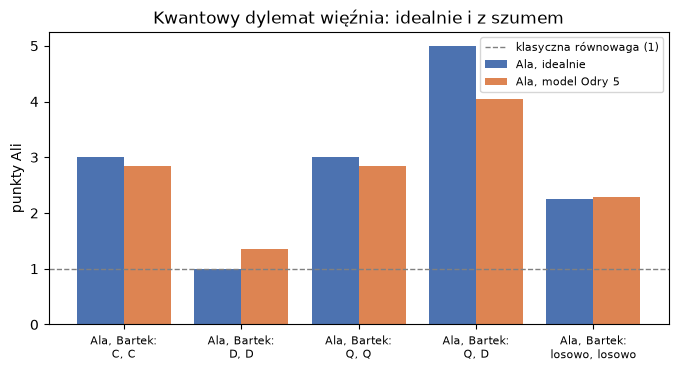

In [14]:
names = list(results)
x = np.arange(len(names))
plt.figure(figsize=(8, 3.8))
plt.bar(x - 0.2, [results[n][0][0] for n in names], 0.4, label="Ala, idealnie", color="#4C72B0")
plt.bar(x + 0.2, [results[n][1][0] for n in names], 0.4, label="Ala, model Odry 5", color="#DD8452")
plt.axhline(1, color="gray", ls="--", lw=1, label="klasyczna równowaga (1)")
plt.xticks(x, [f"Ala, Bartek:\n{n}" for n in names], fontsize=8)
plt.ylabel("punkty Ali"); plt.title("Kwantowy dylemat więźnia: idealnie i z szumem")
plt.legend(fontsize=8); plt.show()

Szum zjada część punktów, najmocniej w (Q, D). Zauważ, że (D, D) z szumem daje **więcej** niż 1:
szum ciągnie każdy wynik w stronę 2.25, czyli w stronę całkiem losowej gry. Mimo to (Q, Q) dalej daje dużo więcej
niż klasyczna zdrada (1, 1).
To tylko 2 kubity, więc na Odrze 5 zostają jeszcze 3 wolne.

> Uczciwie: kwantowa gra to **inna gra**, nie sposób na „rozwiązanie” klasycznego dylematu. Sędzia musi
> splątać kubity i potem je rozplątać, a gracze muszą zgodzić się grać obrotami kubitów.

## 7. Wyzwania

1. **Trzech więźniów na 3 kubitach**: sędzia przygotowuje stan GHZ (jak w notebooku 3). Sprawdź, co robi (Q, Q, Q).
   Podpowiedź: policz, czy dla nieparzystej liczby graczy Q dalej działa.
2. **Pięciu graczy na całej Odrze 5**: gwiazda idealnie pasuje do stanu GHZ (centrum + 4 ramiona).
3. **Uczenie w pełnej przestrzeni**: daj botom z sekcji 4 trzy kąty zamiast dwóch. Czy kręcą się w kółko?
4. **Gra powtarzana**: połącz z botem z notebooka 4. Boty grają 100 rund i pamiętają, co zrobił przeciwnik.
5. **Ile splątania przy szumie**: powtórz wykres z sekcji 3 na `IQMFakeAdonis`. Czy próg się przesuwa?